DS 4002 Project 2:  Forecasting Weekly Influenza-Like Illness Visits


In [3]:
# DS 4002 Project 2: Forecasting Weekly Influenza-Like Illness Visits
# Purpose: Clean CDC influenza data, conduct exploratory analysis,
# develop and validate ARIMA/ARIMAX models, and evaluate the selected
# model on the held-out 2025–2026 influenza season.
# Platform: Google Colab with Python.
# Required input files: Influenza_Data_21-25.csv and Influenza_Data_25-26.csv.
# Instructions: Upload both CSV files when prompted and run all cells in order.
# Outputs: Model tables, predictions, diagnostics, and figures are saved
# in the OUTPUT folder.

# Uploading the Required Data Files
from google.colab import files

cleaned_data = files.upload()

Saving Influenza_Data_21-25.csv to Influenza_Data_21-25 (1).csv
Saving Influenza_Data_25-26.csv to Influenza_Data_25-26.csv


In [4]:
# loading files in, omitting the first row since it is a statement from cdc
import pandas as pd

df1 = pd.read_csv("Influenza_Data_21-25.csv", skiprows=1)
df2 = pd.read_csv("Influenza_Data_25-26.csv", skiprows=1)

In [5]:
#combining and filtering columns
df = pd.concat([df1, df2], ignore_index=True)
df.columns = df.columns.str.strip()
#renaming the columns for weighted ili
df = df[["YEAR", "WEEK", "% WEIGHTED ILI"]].copy()
df.columns = ["Year", "Week", "Weighted_ILI_Percent"]
df.head()

,Year,Week,Weighted_ILI_Percent
0,2021,40,2.04946
1,2021,41,1.95317
2,2021,42,1.92693
3,2021,43,1.97792
4,2021,44,2.14051


In [6]:
#checking for missing values and duplicates

for column in df.columns:
  df[column] = pd.to_numeric(df[column], errors = "coerce")

print(df.isna().sum())
#### all show zero meaning no missing values


#checking for duplicates
df.duplicated().sum()
df = df.drop_duplicates()
print(df.duplicated(subset=["Year", "Week"]).sum())

#### all show zero meaning no duplicated

# checking if weeks are negative or not in between 0-53 by reading through
print (df["Week"])
# checking if percentages are negative or not in between 0-100 by reading through
print (df["Weighted_ILI_Percent"])

Year                    0
Week                    0
Weighted_ILI_Percent    0
dtype: int64
0
0      40
1      41
2      42
3      43
4      44
       ..
256    35
257    36
258    37
259    38
260    39
Name: Week, Length: 261, dtype: int64
0      2.04946
1      1.95317
2      1.92693
3      1.97792
4      2.14051
        ...   
256    1.53043
257    1.58903
258    1.64502
259    1.74685
260    1.84605
Name: Weighted_ILI_Percent, Length: 261, dtype: float64


In [7]:
# sorting chronologically for time series
df = df.sort_values(["Year", "Week"])
print(df)

#checking completed cleaned dataset
df.info
display(df.head(10))
display(df.tail(10))

     Year  Week  Weighted_ILI_Percent
0    2021    40               2.04946
1    2021    41               1.95317
2    2021    42               1.92693
3    2021    43               1.97792
4    2021    44               2.14051
..    ...   ...                   ...
256  2026    35               1.53043
257  2026    36               1.58903
258  2026    37               1.64502
259  2026    38               1.74685
260  2026    39               1.84605

[261 rows x 3 columns]


,Year,Week,Weighted_ILI_Percent
0,2021,40,2.04946
1,2021,41,1.95317
2,2021,42,1.92693
3,2021,43,1.97792
4,2021,44,2.14051
5,2021,45,2.26691
6,2021,46,2.41002
7,2021,47,2.51362
8,2021,48,2.56387
9,2021,49,2.74219


,Year,Week,Weighted_ILI_Percent
251,2026,30,0.866443
252,2026,31,0.873229
253,2026,32,0.954802
254,2026,33,1.131460
255,2026,34,1.355860
256,2026,35,1.530430
257,2026,36,1.589030
258,2026,37,1.645020
259,2026,38,1.746850
260,2026,39,1.846050


**Part II - Varaible Creation & Exploration**

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
#===============================================
# Date and Season Variables
def mmwr_week_start(year, week):
    """Sunday that starts CDC (MMWR) week `week` of `year`.
    MMWR week 1 is the Sunday-Saturday week containing January 4."""
    jan4 = pd.Timestamp(year=int(year), month=1, day=4)
    week1_start = jan4 - pd.Timedelta(days=(jan4.weekday() + 1) % 7)
    return week1_start + pd.Timedelta(weeks=int(week) - 1)

df = df.reset_index(drop=True)
df["Date"] = [mmwr_week_start(y, w) for y, w in zip(df["Year"], df["Week"])]
df = df.sort_values("Date").reset_index(drop=True)

# Check: every row should be exactly 7 days after the previous one
gaps = df["Date"].diff().dt.days.dropna()
print("Rows not 7 days after the previous week:", int((gaps != 7).sum()))
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date(), f"({len(df)} weeks)")

# CDC flu seasons run from MMWR week 40 through week 39 of the next year
df["Season_Start_Year"] = np.where(df["Week"] >= 40, df["Year"], df["Year"] - 1)
df["Season"] = df["Season_Start_Year"].astype(str) + "-" + (df["Season_Start_Year"] + 1).astype(str)
season_start = pd.Series([mmwr_week_start(y, 40) for y in df["Season_Start_Year"]], index=df.index)
df["Season_Week"] = (df["Date"] - season_start).dt.days // 7 + 1   # 1 = week 40
df["Month"] = df["Date"].dt.month
# Active flu period (MMWR weeks 40-20, roughly Oct-May) = 1, off-season = 0
df["Flu_Season"] = ((df["Week"] >= 40) | (df["Week"] <= 20)).astype(int)

display(df.head())


Rows not 7 days after the previous week: 0
Date range: 2021-10-03 to 2026-09-27 (261 weeks)


,Year,Week,Weighted_ILI_Percent,Date,Season_Start_Year,Season,Season_Week,Month,Flu_Season
0,2021,40,2.04946,2021-10-03,2021,2021-2022,1,10,1
1,2021,41,1.95317,2021-10-10,2021,2021-2022,2,10,1
2,2021,42,1.92693,2021-10-17,2021,2021-2022,3,10,1
3,2021,43,1.97792,2021-10-24,2021,2021-2022,4,10,1
4,2021,44,2.14051,2021-10-31,2021,2021-2022,5,10,1


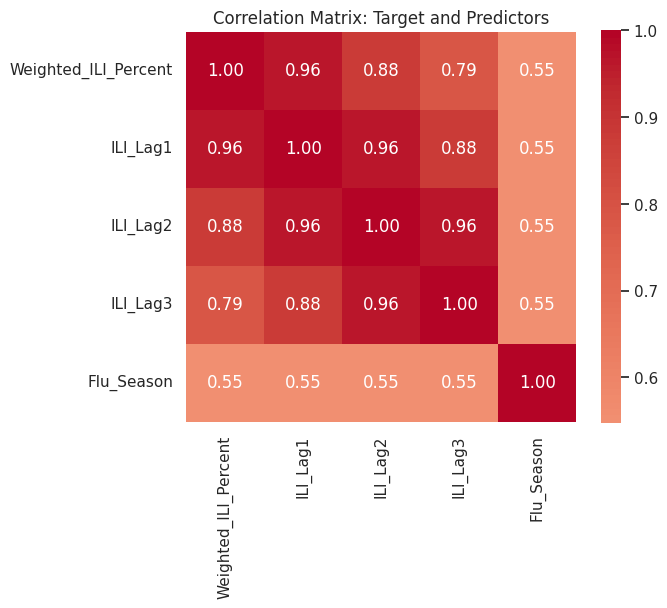

,Date,Year,Week,Weighted_ILI_Percent,ILI_Z,ILI_Lag1,ILI_Lag2,ILI_Lag3,Flu_Season
0,2021-10-24,2021,43,1.97792,-0.459127,1.92693,1.95317,2.04946,1
1,2021-10-31,2021,44,2.14051,-0.355054,1.97792,1.92693,1.95317,1
2,2021-11-07,2021,45,2.26691,-0.274145,2.14051,1.97792,1.92693,1
3,2021-11-14,2021,46,2.41002,-0.182541,2.26691,2.14051,1.97792,1
4,2021-11-21,2021,47,2.51362,-0.116227,2.41002,2.26691,2.14051,1


In [9]:
#===============================================
# Variable Organization
#===============================================
target = "Weighted_ILI_Percent"

# Predictors: ILI from 1, 2 and 3 weeks earlier
for k in [1, 2, 3]:
    df[f"ILI_Lag{k}"] = df[target].shift(k)

# Normalized score: z-score of ILI (0 = average week)
df["ILI_Z"] = (df[target] - df[target].mean()) / df[target].std()

FEATURES = ["ILI_Lag1", "ILI_Lag2", "ILI_Lag3", "Flu_Season"]

# FIGURE A: Correlation heatmap of target and predictors
corr = df[[target] + FEATURES].corr()
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Correlation Matrix: Target and Predictors")
plt.tight_layout()
plt.savefig("fig_a_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# Final modeling dataset (first 3 weeks dropped, since they have no lag history)
model_df = df[["Date", "Year", "Week", target, "ILI_Z"] + FEATURES].dropna().reset_index(drop=True)
display(model_df.head())

count    261.000
mean       2.695
std        1.562
min        0.866
25%        1.682
50%        2.099
75%        3.252
max        8.299
Name: Weighted_ILI_Percent, dtype: float64

IQR bounds: [-0.67, 5.61] -> 21 weeks flagged


,Date,Season,Week,Weighted_ILI_Percent
57,2022-11-06,2022-2023,45,5.73522
58,2022-11-13,2022-2023,46,5.91793
59,2022-11-20,2022-2023,47,7.42531
60,2022-11-27,2022-2023,48,7.21822
61,2022-12-04,2022-2023,49,6.87034
62,2022-12-11,2022-2023,50,6.29772
63,2022-12-18,2022-2023,51,6.00293
115,2023-12-17,2023-2024,51,6.23157
116,2023-12-24,2023-2024,52,6.79620
117,2023-12-31,2023-2024,1,5.71536


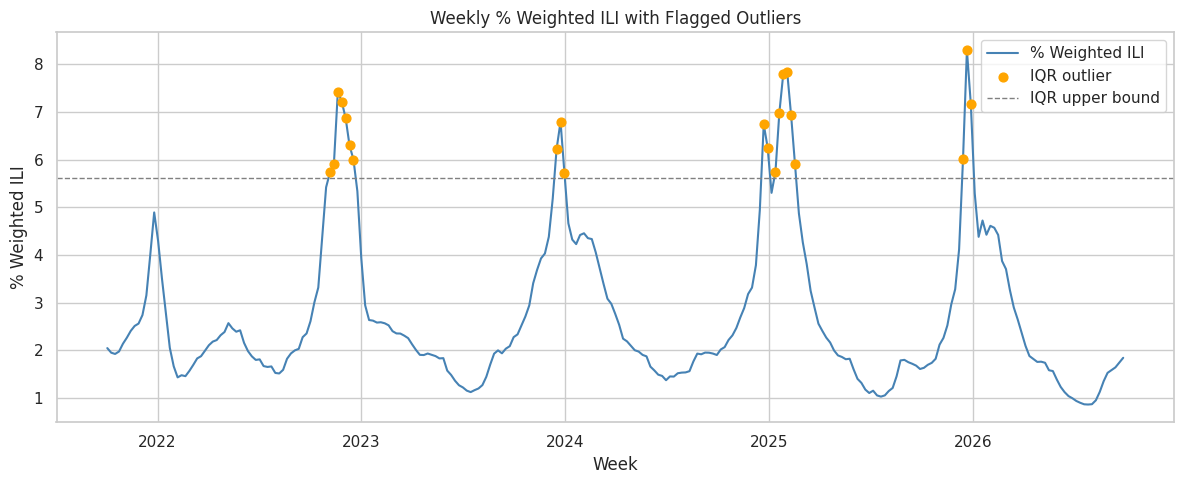

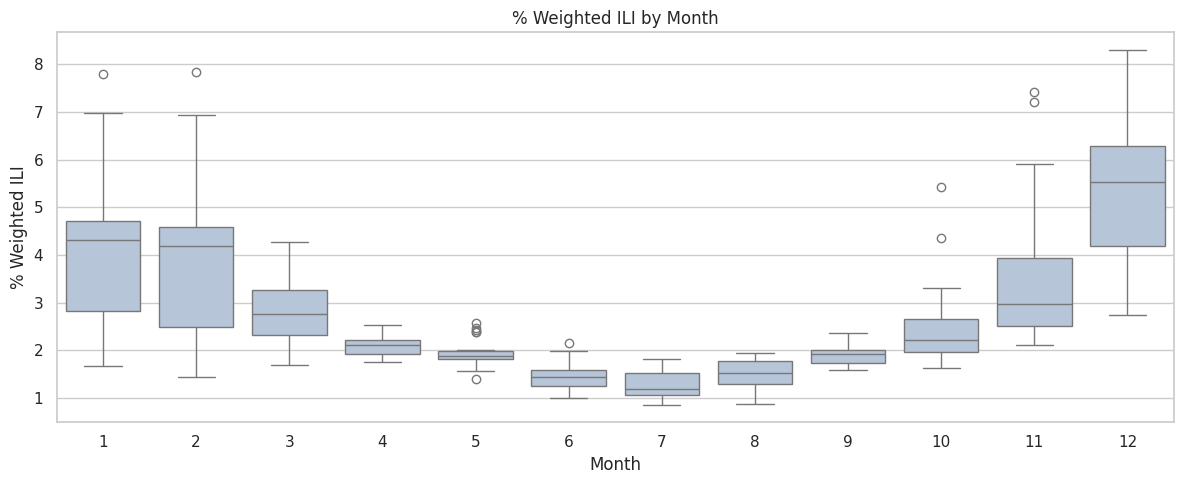

In [10]:
#===============================================
# i) Checking for Outliers
#===============================================
y = df["Weighted_ILI_Percent"]
print(y.describe().round(3))

# Establishing IQR
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
df["Outlier_IQR"] = ((y < lower) | (y > upper)).astype(int)
print(f"\nIQR bounds: [{lower:.2f}, {upper:.2f}] -> {df['Outlier_IQR'].sum()} weeks flagged")
display(df.loc[df["Outlier_IQR"] == 1, ["Date", "Season", "Week", "Weighted_ILI_Percent"]])

# FIGURE 1: time series with IQR outliers marked in orange
fig, ax = plt.subplots()
ax.plot(df["Date"], y, color="steelblue", lw=1.5, label="% Weighted ILI")
ax.scatter(df.loc[df["Outlier_IQR"] == 1, "Date"], y[df["Outlier_IQR"] == 1],
           color="orange", s=40, zorder=3, label="IQR outlier")
ax.axhline(upper, ls="--", color="gray", lw=1, label="IQR upper bound")
ax.set(title="Weekly % Weighted ILI with Flagged Outliers", xlabel="Week", ylabel="% Weighted ILI")
ax.legend()
plt.tight_layout()
plt.savefig("fig_i_1_outliers_time_series.png", dpi=300, bbox_inches="tight")
plt.show()

# FIGURE 2: boxplot by month -- shows the outliers all fall in winter flu months
fig, ax = plt.subplots()
sns.boxplot(data=df, x="Month", y="Weighted_ILI_Percent", color="lightsteelblue", ax=ax)
ax.set(title="% Weighted ILI by Month", ylabel="% Weighted ILI")
plt.tight_layout()
plt.savefig("fig_i_2_boxplot_by_month.png", dpi=300, bbox_inches="tight")
plt.show()

# Outliers are kept: these are official CDC values, and the flagged weeks
# are real flu-season peaks, which is exactly what the model needs to predict.

Skewness: 1.495   Kurtosis: 1.652
Skewness of log(ILI): 0.512


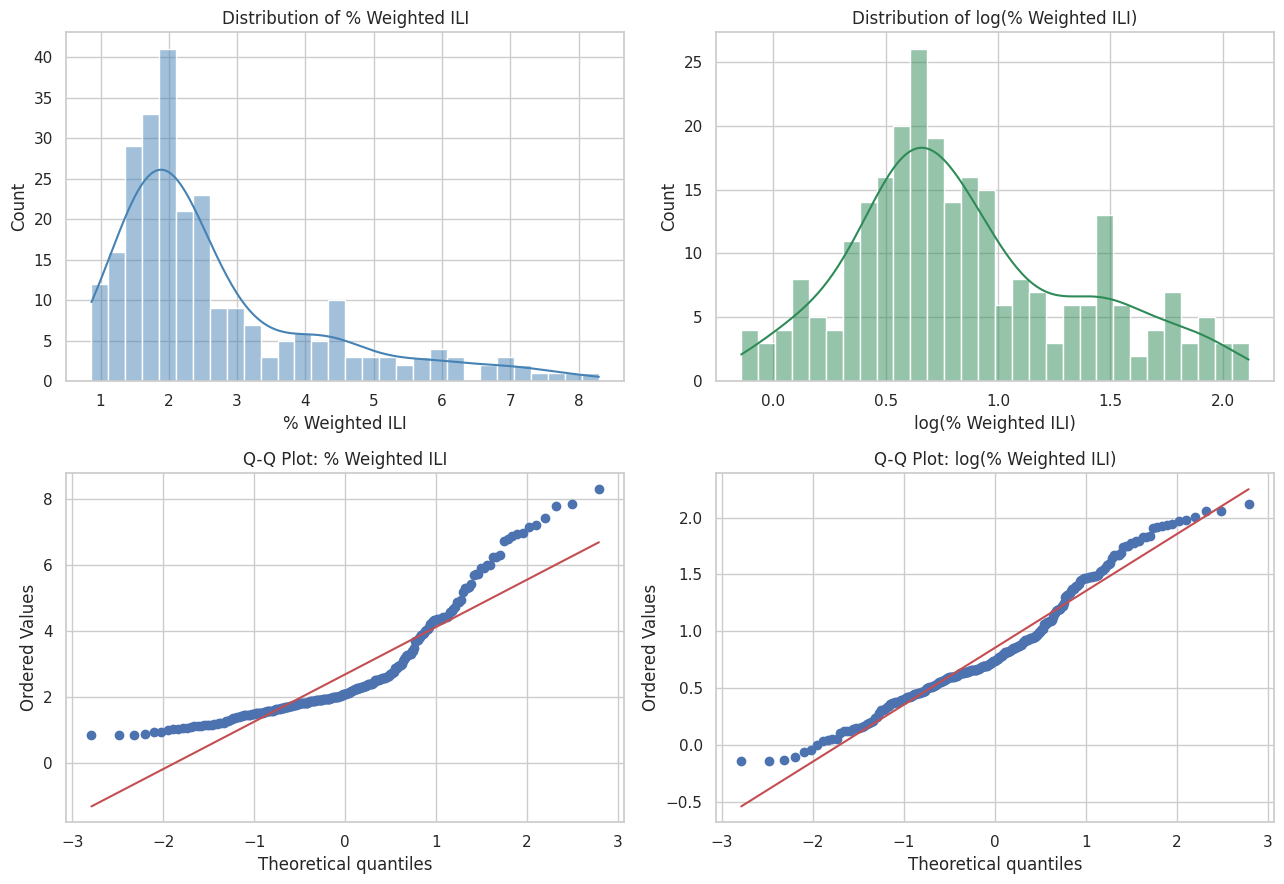

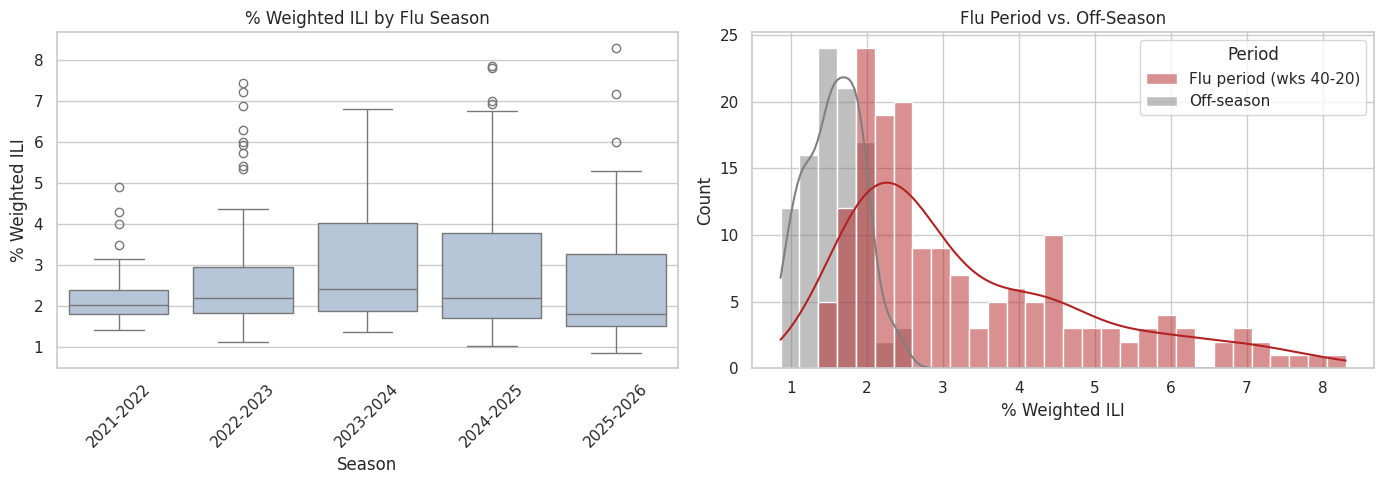

In [11]:
#===============================================
# ii) Distribution Plots
#===============================================

# Summary statistics
print(f"Skewness: {stats.skew(y):.3f}   Kurtosis: {stats.kurtosis(y):.3f}")
print(f"Skewness of log(ILI): {stats.skew(np.log(y)):.3f}")
# Skewness: 0 = symmetric; > 0 = long right tail (a few very high flu-peak weeks)
# Same skewness check after a log transform -- closer to 0 means more symmetric
# Kurtosis: 0 = normal-like tails; > 0 = heavier tails / more extreme values


# FIGURE 1: 2x2 grid comparing raw vs. log-transformed ILI
#   [Top-left]  Histogram of raw % weighted ILI
#   [Top-right] Histogram of log(% weighted ILI)
#   [Bottom-left]  Q-Q plot of raw % weighted ILI
#   [Bottom-right] Q-Q plot of log(% weighted ILI)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Top-left: histogram + KDE (smoothed density curve) of the raw values.
sns.histplot(y, kde=True, bins=30, color="steelblue", ax=axes[0, 0])
axes[0, 0].set(title="Distribution of % Weighted ILI", xlabel="% Weighted ILI")

# Top-right: same histogram after taking the natural log.
sns.histplot(np.log(y), kde=True, bins=30, color="seagreen", ax=axes[0, 1])
axes[0, 1].set(title="Distribution of log(% Weighted ILI)", xlabel="log(% Weighted ILI)")

# Bottom-left: Q-Q plot of the raw values against a normal distribution.
stats.probplot(y, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Q-Q Plot: % Weighted ILI")

# Bottom-right: Q-Q plot of the log values.
stats.probplot(np.log(y), dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q Plot: log(% Weighted ILI)")

plt.tight_layout()
plt.savefig("fig_ii_1_2x2_grid.png", dpi=300, bbox_inches="tight")  # save PNG
plt.show()

# FIGURE 2: How the distribution differs across time periods
#   [Left]  Boxplot of ILI for each flu season (e.g. 2021-2022, 2022-2023, ...)
#   [Right] Overlapping histograms: active flu period vs. off-season

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: one box per flu season (week 40 through week 39 of the next year).
sns.boxplot(data=df, x="Season", y="Weighted_ILI_Percent", color="lightsteelblue", ax=axes[0])
axes[0].set(title="% Weighted ILI by Flu Season", ylabel="% Weighted ILI")
axes[0].tick_params(axis="x", rotation=45)   # rotate season labels so they don't overlap

# Right: two overlapping histograms split by the Flu_Season flag
df["Period"] = df["Flu_Season"].map({1: "Flu period (wks 40-20)", 0: "Off-season"})
sns.histplot(data=df, x="Weighted_ILI_Percent", hue="Period", kde=True, bins=30,
             palette={"Flu period (wks 40-20)": "firebrick", "Off-season": "gray"},
             ax=axes[1])
axes[1].set(title="Flu Period vs. Off-Season", xlabel="% Weighted ILI")

plt.tight_layout()
plt.savefig("fig_ii_2_distribution_by_season_and_period.png", dpi=300, bbox_inches="tight")  # save PNG
plt.show()

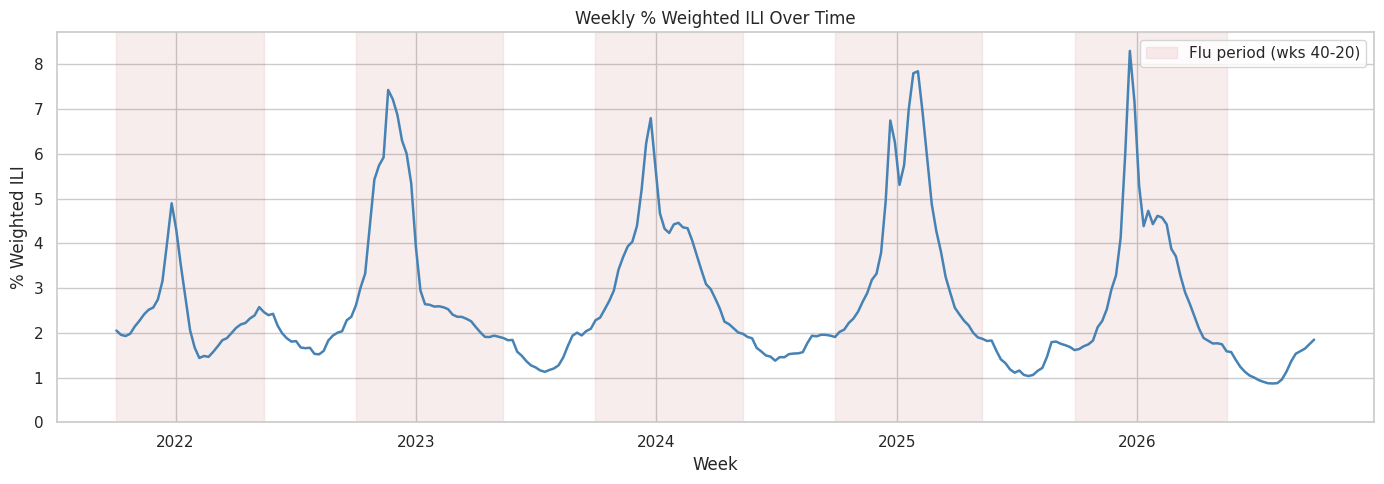

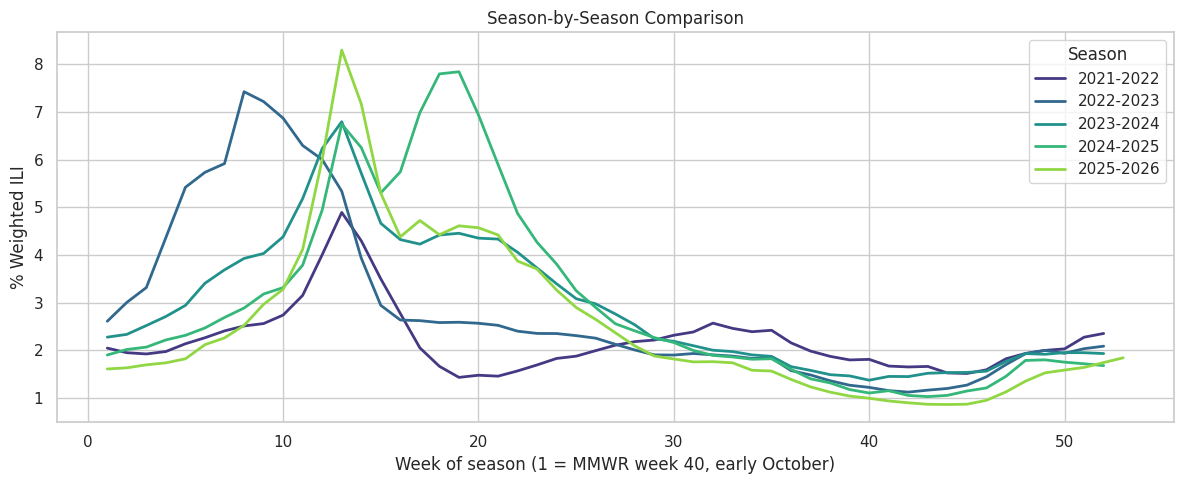

,Season,Peak_Date,Peak_MMWR_Week,Season_Week,Peak_ILI,Weeks_in_Data
0,2021-2022,2021-12-26,52,13,4.89397,52
1,2022-2023,2022-11-20,47,8,7.42531,52
2,2023-2024,2023-12-24,52,13,6.79620,52
3,2024-2025,2025-02-02,6,19,7.84378,52
4,2025-2026,2025-12-21,52,13,8.29853,53


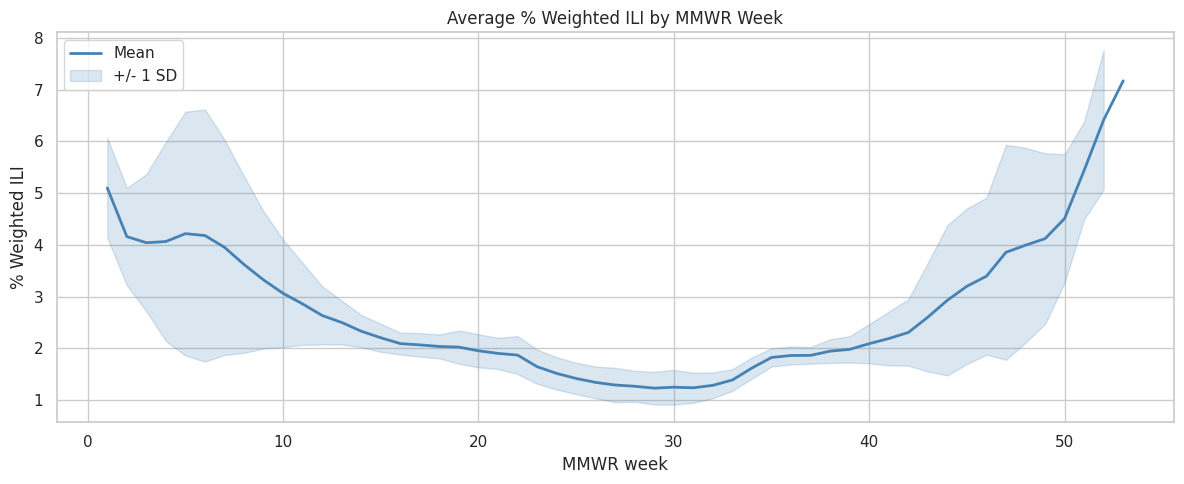

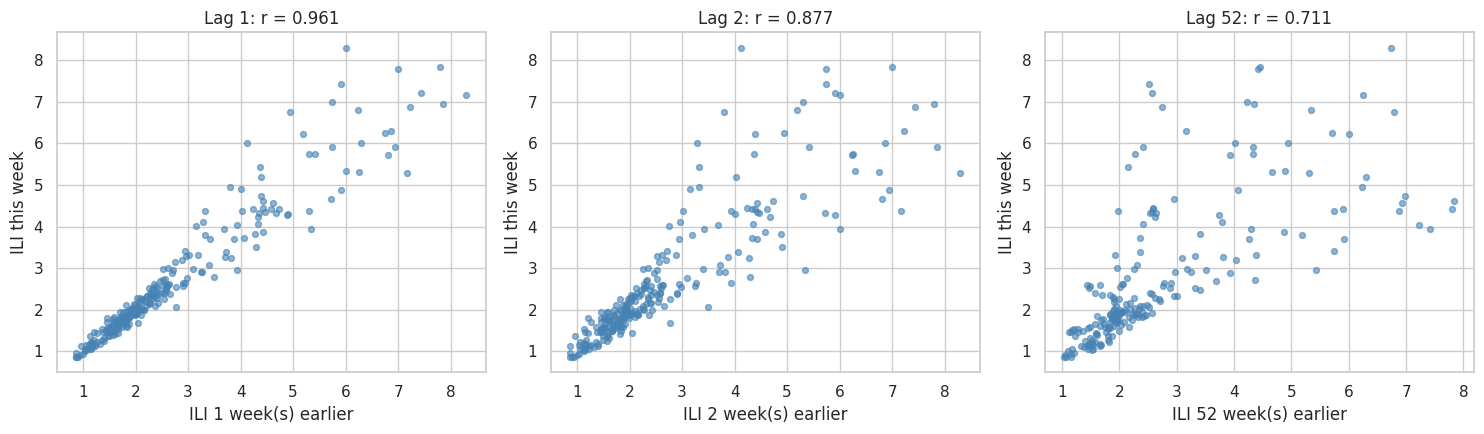

In [12]:
#===============================================
# iii) EDAs & More Plots
#===============================================

# FIGURE 3: Full time series with flu periods shaded
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df["Date"], y, color="steelblue", lw=1.8)
# Shade every week where Flu_Season == 1, from 0 up to just above the max value
ax.fill_between(df["Date"], 0, y.max() * 1.05, where=df["Flu_Season"] == 1,
                color="firebrick", alpha=0.08, label="Flu period (wks 40-20)")
ax.set(title="Weekly % Weighted ILI Over Time", xlabel="Week", ylabel="% Weighted ILI",
       ylim=(0, y.max() * 1.05))
ax.legend()
plt.tight_layout()
plt.savefig("fig_iii_1_time_series.png", dpi=300, bbox_inches="tight")  # save PNG
plt.show()


# FIGURE 4: Season-by-season comparison (one line per flu season)
fig, ax = plt.subplots()
sns.lineplot(data=df, x="Season_Week", y="Weighted_ILI_Percent", hue="Season",
             palette="viridis", lw=2, ax=ax)
ax.set(title="Season-by-Season Comparison",
       xlabel="Week of season (1 = MMWR week 40, early October)", ylabel="% Weighted ILI")
plt.tight_layout()
plt.savefig("fig_iii_2_season_comparison.png", dpi=300, bbox_inches="tight")  # save PNG
plt.show()


# TABLE 1: Peak week of each flu season
peaks = (df.loc[df.groupby("Season")["Weighted_ILI_Percent"].idxmax(),
                ["Season", "Date", "Week", "Season_Week", "Weighted_ILI_Percent"]]
           .rename(columns={"Weighted_ILI_Percent": "Peak_ILI", "Date": "Peak_Date",
                            "Week": "Peak_MMWR_Week"})
           .reset_index(drop=True))
peaks = peaks.merge(df.groupby("Season").size().rename("Weeks_in_Data"), on="Season")
display(peaks)


# FIGURE 5: Average seasonal profile by MMWR week
weekly = df.groupby("Week")["Weighted_ILI_Percent"].agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots()
ax.plot(weekly["Week"], weekly["mean"], color="steelblue", lw=2, label="Mean")
ax.fill_between(weekly["Week"], weekly["mean"] - weekly["std"], weekly["mean"] + weekly["std"],
                color="steelblue", alpha=0.2, label="+/- 1 SD")
ax.set(title="Average % Weighted ILI by MMWR Week", xlabel="MMWR week", ylabel="% Weighted ILI")
ax.legend()
plt.tight_layout()
plt.savefig("fig_iii_3_avg_by_mmwr_week.png", dpi=300, bbox_inches="tight")  # save PNG
plt.show()


# FIGURE 6: Lag scatter plots (3 panels)
#   [Left]   This week's ILI vs. ILI 1 week earlier
#   [Middle] This week's ILI vs. ILI 2 weeks earlier
#   [Right]  This week's ILI vs. ILI 52 weeks earlier (same week last year)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, k in zip(axes, [1, 2, 52]):
    lagged = y.shift(k)   # shift(k) = the value from k weeks earlier
    ax.scatter(lagged, y, alpha=0.6, s=18, color="steelblue")
    ax.set(title=f"Lag {k}: r = {y.corr(lagged):.3f}",
           xlabel=f"ILI {k} week(s) earlier", ylabel="ILI this week")
plt.tight_layout()
plt.savefig("fig_iii_4_lag_scatter.png", dpi=300, bbox_inches="tight")  # save PNG
plt.show()

Part III - Model Development: ARIMA & ARIMAX

In [13]:
# Part III setup: import the libraries used for model development.
# Standard-library modules: version info, JSON output, platform details,
# and warning capture during model fitting.
import sys
import json
import platform
import warnings

# Path manages the OUTPUT folder; version() reads installed package versions.
from pathlib import Path
from importlib.metadata import version

# Core data-analysis and plotting libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# statsmodels tools: SARIMAX fits both ARIMA and ARIMAX models,
# adfuller/kpss test stationarity, plot_acf/plot_pacf show serial
# dependence, and acorr_ljungbox tests residual autocorrelation.
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

# Create a folder for the model tables and figures.
OUTPUT = Path("OUTPUT")
OUTPUT.mkdir(exist_ok=True)

# Record the software versions used for reproducibility.
package_versions = {
    "Python": sys.version.split()[0],
    "Platform": platform.platform()
}

# Add the installed version of each analysis package to the record.
for package in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib"]:
    package_versions[package] = version(package)

# Print the versions in the notebook and save them to OUTPUT so the
# computing environment is documented.
print(json.dumps(package_versions, indent=2))

with open(OUTPUT / "model_package_versions.json", "w") as file:
    json.dump(package_versions, file, indent=2)

{
  "Python": "3.13.16",
  "Platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "scipy": "1.16.3",
  "statsmodels": "0.15.0",
  "matplotlib": "3.10.0"
}


In [14]:
#===============================================
# Preparing the Training Data
#===============================================

# Use the original ILI values rather than the normalized score.
# ARIMA does not require the lag columns created during exploration.
required_columns = ["Year", "Week", "Weighted_ILI_Percent"]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}. "
        "Run the data cleaning cells first."
    )

training_data = df[required_columns].copy()

for column in required_columns:
    training_data[column] = pd.to_numeric(
        training_data[column],
        errors="raise"
    )

if training_data.isna().any().any():
    raise ValueError("Missing values found in the model input.")

if not (
    (training_data["Year"] % 1 == 0)
    & (training_data["Week"] % 1 == 0)
).all():
    raise ValueError("Year and Week must contain whole numbers.")


# Convert reporting year and week to the Sunday starting that week.
def get_week_start(year, week):
    year = int(year)
    week = int(week)

    january_fourth = pd.Timestamp(year, 1, 4)

    first_week = january_fourth - pd.Timedelta(
        days=(january_fourth.dayofweek + 1) % 7
    )

    next_january_fourth = pd.Timestamp(year + 1, 1, 4)

    next_first_week = next_january_fourth - pd.Timedelta(
        days=(next_january_fourth.dayofweek + 1) % 7
    )

    weeks_in_year = (next_first_week - first_week).days // 7

    if not 1 <= week <= weeks_in_year:
        raise ValueError(f"Invalid reporting year/week: {year}/{week}")

    return first_week + pd.Timedelta(weeks=week - 1)


training_data["Date"] = [
    get_week_start(year, week)
    for year, week in zip(
        training_data["Year"],
        training_data["Week"]
    )
]

# Restrict development to 2021 week 40 through 2025 week 39.
training_data = training_data.loc[
    (training_data["Date"] >= get_week_start(2021, 40))
    & (training_data["Date"] < get_week_start(2025, 40))
].copy()

training_data = (
    training_data
    .sort_values("Date")
    .set_index("Date")
)

if training_data.index.duplicated().any():
    raise ValueError("Duplicate reporting weeks found.")

if len(training_data) != 208:
    raise ValueError(
        f"Expected 208 training weeks, found {len(training_data)}. "
        "Check which dataset was loaded."
    )

weekly_gaps = training_data.index.to_series().diff().dropna()

if not weekly_gaps.eq(pd.Timedelta(days=7)).all():
    raise ValueError("Missing or irregular reporting weeks found.")

if not training_data["Weighted_ILI_Percent"].between(0, 100).all():
    raise ValueError("ILI percentages must be between 0 and 100.")

training_data = training_data.asfreq("W-SUN")
y_train = training_data["Weighted_ILI_Percent"]

# Begin validation at the start of the 2024–2025 season.
validation_start = get_week_start(2024, 40)
split_position = y_train.index.get_loc(validation_start)

initial_train = y_train.iloc[:split_position]

print("Total training weeks:", len(y_train))
print("Initial fitting weeks:", len(initial_train))
print("Validation weeks:", len(y_train) - split_position)

display(training_data.head())

Total training weeks: 208
Initial fitting weeks: 156
Validation weeks: 52


,Year,Week,Weighted_ILI_Percent
Date,,,
2021-10-03,2021,40,2.04946
2021-10-10,2021,41,1.95317
2021-10-17,2021,42,1.92693
2021-10-24,2021,43,1.97792
2021-10-31,2021,44,2.14051


In [15]:
#===============================================
# Holiday Variables for ARIMAX
#===============================================

def create_holiday_features(dates):
    """
    Identify reporting weeks containing Thanksgiving,
    Christmas, and New Year's Day.
    """
    dates = pd.DatetimeIndex(dates)

    holiday_features = pd.DataFrame(
        0.0,
        index=dates,
        columns=["Thanksgiving", "Christmas", "New_Year"]
    )

    for year in range(dates.min().year, dates.max().year + 2):

        # Thanksgiving falls on the fourth Thursday in November.
        november_first = pd.Timestamp(year, 11, 1)

        thanksgiving = november_first + pd.Timedelta(
            days=(3 - november_first.dayofweek) % 7 + 21
        )

        holiday_dates = {
            "Thanksgiving": thanksgiving,
            "Christmas": pd.Timestamp(year, 12, 25),
            "New_Year": pd.Timestamp(year, 1, 1)
        }

        for holiday_name, holiday_date in holiday_dates.items():

            # Reporting weeks run from Sunday through Saturday.
            contains_holiday = (
                (dates <= holiday_date)
                & (dates + pd.Timedelta(days=6) >= holiday_date)
            )

            holiday_features.loc[
                contains_holiday, holiday_name
            ] = 1.0

    return holiday_features


# Calendar information is known before forecasting each target week.
X_train = create_holiday_features(y_train.index)

model_training_data = pd.concat(
    [training_data, X_train],
    axis=1
)

model_training_data.to_csv(
    OUTPUT / "model_training_data.csv",
    index_label="Date"
)

display(
    model_training_data.loc[
        X_train.sum(axis=1) > 0
    ].head(12)
)

,Year,Week,Weighted_ILI_Percent,Thanksgiving,Christmas,New_Year
Date,,,,,,
2021-11-21,2021,47,2.51362,1.0,0.0,0.0
2021-12-19,2021,51,4.00700,0.0,1.0,0.0
2021-12-26,2021,52,4.89397,0.0,0.0,1.0
2022-11-20,2022,47,7.42531,1.0,0.0,0.0
2022-12-25,2022,52,5.33838,0.0,1.0,0.0
2023-01-01,2023,1,3.93482,0.0,0.0,1.0
2023-11-19,2023,47,3.92958,1.0,0.0,0.0
2023-12-24,2023,52,6.79620,0.0,1.0,0.0
2023-12-31,2024,1,5.71536,0.0,0.0,1.0


/tmp/ipykernel_975/3289899649.py:17: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series, autolag="AIC")
/tmp/ipykernel_975/3289899649.py:17: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series, autolag="AIC")


,Series,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value,KPSS note
0,Original ILI,-3.431926,9.917501e-03,0.072654,0.1,The test statistic is outside of the range of ...
1,First difference,-6.056882,1.239052e-07,0.045416,0.1,The test statistic is outside of the range of ...


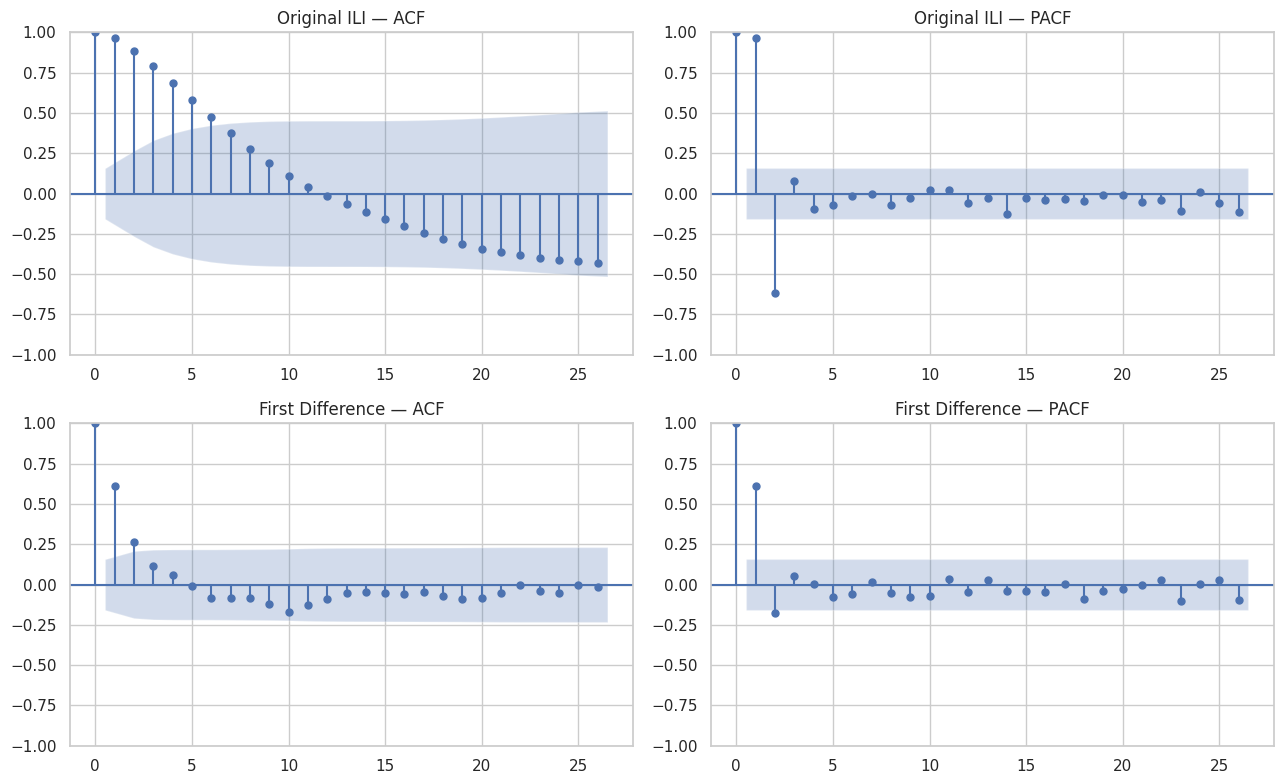

In [16]:
#===============================================
# i) Stationarity Checks
#===============================================

# Check the initial fitting period before evaluating forecasts.
# ADF: the null hypothesis is a unit root.
# KPSS: the null hypothesis is stationarity.
stationarity_results = []

series_to_check = {
    "Original ILI": initial_train,
    "First difference": initial_train.diff().dropna()
}

for name, series in series_to_check.items():

    adf_result = adfuller(series, autolag="AIC")

    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always")

        kpss_result = kpss(
            series,
            regression="c",
            nlags="auto"
        )

    stationarity_results.append({
        "Series": name,
        "ADF statistic": adf_result[0],
        "ADF p-value": adf_result[1],
        "KPSS statistic": kpss_result[0],
        "KPSS p-value": kpss_result[1],
        "KPSS note": "; ".join(
            str(message.message) for message in captured
        )
    })

stationarity_table = pd.DataFrame(stationarity_results)

display(stationarity_table)

stationarity_table.to_csv(
    OUTPUT / "model_stationarity_checks.csv",
    index=False
)


#===============================================
# ii) ACF and PACF Plots
#===============================================

# Compare dependence in the original and differenced series.
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

plot_acf(
    initial_train,
    lags=26,
    ax=axes[0, 0]
)

plot_pacf(
    initial_train,
    lags=26,
    method="ywm",
    ax=axes[0, 1]
)

plot_acf(
    initial_train.diff().dropna(),
    lags=26,
    ax=axes[1, 0]
)

plot_pacf(
    initial_train.diff().dropna(),
    lags=26,
    method="ywm",
    ax=axes[1, 1]
)

axes[0, 0].set_title("Original ILI — ACF")
axes[0, 1].set_title("Original ILI — PACF")
axes[1, 0].set_title("First Difference — ACF")
axes[1, 1].set_title("First Difference — PACF")

plt.tight_layout()

plt.savefig(
    OUTPUT / "model_acf_pacf.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
#===============================================
# iii) ARIMA and ARIMAX Model Comparison
#===============================================

# Orders are written as (p, d, q): p = autoregressive terms,
# d = number of differences, q = moving-average terms.
# d = 0 models the original series; d = 1 models week-to-week changes.
# Compare the same five orders for both model families.
candidate_orders = [
    (1, 0, 0),
    (2, 0, 0),
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1)
]


# Helper function: fit one candidate model on the data available so far.
# Returns the fitted model and any warning messages produced.
def fit_candidate(history, holiday_history, order, family):
    """
    Fit ARIMA or ARIMAX using the same state-space implementation.
    ARIMAX includes holiday regressors with ARIMA errors.
    """
    # SARIMAX without seasonal terms is an ARIMA model (no exog) or an
    # ARIMAX model (holiday indicators as exogenous regressors).
    # Undifferenced models (d = 0) include a constant; differenced models
    # (d = 1) do not include drift. The stationarity and invertibility
    # constraints keep parameter estimates in a valid range.
    model = SARIMAX(
        history,
        exog=holiday_history if family == "ARIMAX" else None,
        order=order,
        trend="c" if order[1] == 0 else "n",
        enforce_stationarity=True,
        enforce_invertibility=True
    )

    # Capture warnings (e.g., convergence messages) instead of printing
    # them, so they can be saved to the warning log.
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always")

        # First attempt: default optimizer, up to 250 iterations.
        fitted_model = model.fit(
            disp=False,
            maxiter=250
        )

        # Retry models that do not converge on the first attempt.
        if not fitted_model.mle_retvals.get("converged", False):
            fitted_model = model.fit(
                start_params=fitted_model.params,
                method="powell",
                disp=False,
                maxiter=500
            )

    # If the model still has not converged, raise an error; the validation
    # loop below counts this as a failed fit.
    if not fitted_model.mle_retvals.get("converged", False):
        raise RuntimeError("Model did not converge after retry.")

    # Keep each unique warning message once.
    messages = sorted({
        str(message.message) for message in captured
    })

    return fitted_model, messages


# Lists that collect results for every model and validation week.
comparison_rows = []
prediction_rows = []
warning_rows = []

# Validation period: the 2024–2025 season (last 52 training weeks).
# split_position is the index of the first validation week.
actual_validation = y_train.iloc[split_position:].to_numpy()

# Baseline prediction: the previous week's observed ILI.
naive_predictions = y_train.iloc[
    split_position - 1:-1
].to_numpy()

# Baseline MAE: average absolute difference between the actual values
# and the previous-week predictions. Models are compared against this.
naive_mae = np.mean(
    np.abs(actual_validation - naive_predictions)
)

# Evaluate every combination of model family and order.
for family in ["ARIMA", "ARIMAX"]:
    for order in candidate_orders:

        model_name = f"{family}{order}"
        forecasts = []
        failed_fits = 0

        # Expand the fitting window by one observation each week.
        for position in range(split_position, len(y_train)):

            # Fit only on weeks before the target week, so no future data is used.
            history = y_train.iloc[:position]
            holiday_history = X_train.iloc[:position]

            # Holiday indicators for the week being forecast. These are known in
            # advance because they come from the calendar.
            target_holidays = X_train.iloc[
                position:position + 1
            ]

            # Fit the model; any error is caught below and logged as a failed fit.
            try:
                fitted_model, messages = fit_candidate(
                    history,
                    holiday_history,
                    order,
                    family
                )

                # Only calendar information from the target week is used.
                forecast_result = fitted_model.forecast(
                    steps=1,
                    exog=(
                        target_holidays
                        if family == "ARIMAX"
                        else None
                    )
                )

                # Convert the forecast result to a single number.
                forecast = float(
                    np.asarray(forecast_result).reshape(-1)[0]
                )

                # Treat infinite or missing forecasts as failures.
                if not np.isfinite(forecast):
                    raise ValueError("Nonfinite forecast.")

                # Save any non-fatal warnings from this fit to the warning log.
                for message in messages:
                    warning_rows.append({
                        "Model": model_name,
                        "Date": y_train.index[position],
                        "Message": message
                    })

            # If fitting or forecasting fails, record NaN and log the error.
            except Exception as error:
                forecast = np.nan
                failed_fits += 1

                warning_rows.append({
                    "Model": model_name,
                    "Date": y_train.index[position],
                    "Message": str(error)
                })

            # Store this week's forecast with the actual value and the
            # previous-week baseline prediction.
            forecasts.append(forecast)

            prediction_rows.append({
                "Model": model_name,
                "Date": y_train.index[position],
                "Actual": float(y_train.iloc[position]),
                "Prediction": forecast,
                "Naive": float(y_train.iloc[position - 1])
            })

        # A model must forecast every validation week to be eligible.
        if failed_fits == 0:
            mae = float(
                np.mean(
                    np.abs(
                        actual_validation - np.asarray(forecasts)
                    )
                )
            )
        else:
            mae = np.nan

        # Summarize this candidate: validation MAE and percentage improvement
        # relative to the naive baseline.
        comparison_rows.append({
            "Model": model_name,
            "Family": family,
            "p": order[0],
            "d": order[1],
            "q": order[2],
            "Validation_MAE": mae,
            "Naive_MAE": naive_mae,
            "Improvement_percent": 100 * (1 - mae / naive_mae),
            "Failed_fits": failed_fits
        })

        # Print progress so long runs show which models have finished.
        print(
            f"{model_name}: MAE = {mae:.4f}; "
            f"failed fits = {failed_fits}"
        )

# Rank candidates from lowest to highest validation MAE;
# models with failed fits are placed last.
comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("Validation_MAE", na_position="last")
    .reset_index(drop=True)
)

# Combine the weekly predictions into one table with proper dates.
validation_predictions = pd.DataFrame(prediction_rows)
validation_predictions["Date"] = pd.to_datetime(
    validation_predictions["Date"]
)

# Combine all logged warnings and errors into one table.
fit_warnings = pd.DataFrame(
    warning_rows,
    columns=["Model", "Date", "Message"]
)

# Save the comparison, weekly predictions, and warning log to OUTPUT.
comparison.to_csv(
    OUTPUT / "model_validation_comparison.csv",
    index=False
)

validation_predictions.to_csv(
    OUTPUT / "model_validation_predictions.csv",
    index=False
)

fit_warnings.to_csv(
    OUTPUT / "model_fit_warnings.csv",
    index=False
)

# Show the ranked comparison table.
display(comparison)

ARIMA(1, 0, 0): MAE = 0.3247; failed fits = 0
ARIMA(2, 0, 0): MAE = 0.2344; failed fits = 0
ARIMA(1, 1, 0): MAE = 0.2367; failed fits = 0
ARIMA(0, 1, 1): MAE = 0.2323; failed fits = 0
ARIMA(1, 1, 1): MAE = 0.2210; failed fits = 0
ARIMAX(1, 0, 0): MAE = 0.2953; failed fits = 0
ARIMAX(2, 0, 0): MAE = 0.2077; failed fits = 0
ARIMAX(1, 1, 0): MAE = 0.2093; failed fits = 0
ARIMAX(0, 1, 1): MAE = 0.2173; failed fits = 0
ARIMAX(1, 1, 1): MAE = 0.1994; failed fits = 0


,Model,Family,p,d,q,Validation_MAE,Naive_MAE,Improvement_percent,Failed_fits
0,"ARIMAX(1, 1, 1)",ARIMAX,1,1,1,0.199352,0.320485,37.796672,0
1,"ARIMAX(2, 0, 0)",ARIMAX,2,0,0,0.207666,0.320485,35.202615,0
2,"ARIMAX(1, 1, 0)",ARIMAX,1,1,0,0.209335,0.320485,34.681810,0
3,"ARIMAX(0, 1, 1)",ARIMAX,0,1,1,0.217323,0.320485,32.189225,0
4,"ARIMA(1, 1, 1)",ARIMA,1,1,1,0.220987,0.320485,31.045933,0
5,"ARIMA(0, 1, 1)",ARIMA,0,1,1,0.232348,0.320485,27.500923,0
6,"ARIMA(2, 0, 0)",ARIMA,2,0,0,0.234424,0.320485,26.853246,0
7,"ARIMA(1, 1, 0)",ARIMA,1,1,0,0.236698,0.320485,26.143826,0
8,"ARIMAX(1, 0, 0)",ARIMAX,1,0,0,0.295263,0.320485,7.869770,0
9,"ARIMA(1, 0, 0)",ARIMA,1,0,0,0.324658,0.320485,-1.302140,0



Selected ARIMA(1, 1, 1)
                                SARIMAX Results                                 
Dep. Variable:     Weighted_ILI_Percent   No. Observations:                  208
Model:                 SARIMAX(1, 1, 1)   Log Likelihood                 -49.001
Date:                  Fri, 23 Oct 2026   AIC                            104.003
Time:                          18:10:18   BIC                            114.001
Sample:                      10-03-2021   HQIC                           108.046
                           - 09-21-2025                                         
Covariance Type:                    opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3441      0.056      6.187      0.000       0.235       0.453
ma.L1          0.4336      0.063      6.923      0.000       0.311       0.556
sigma2     

,lb_stat,lb_pvalue
10,7.587089,0.474807
20,11.511907,0.871386


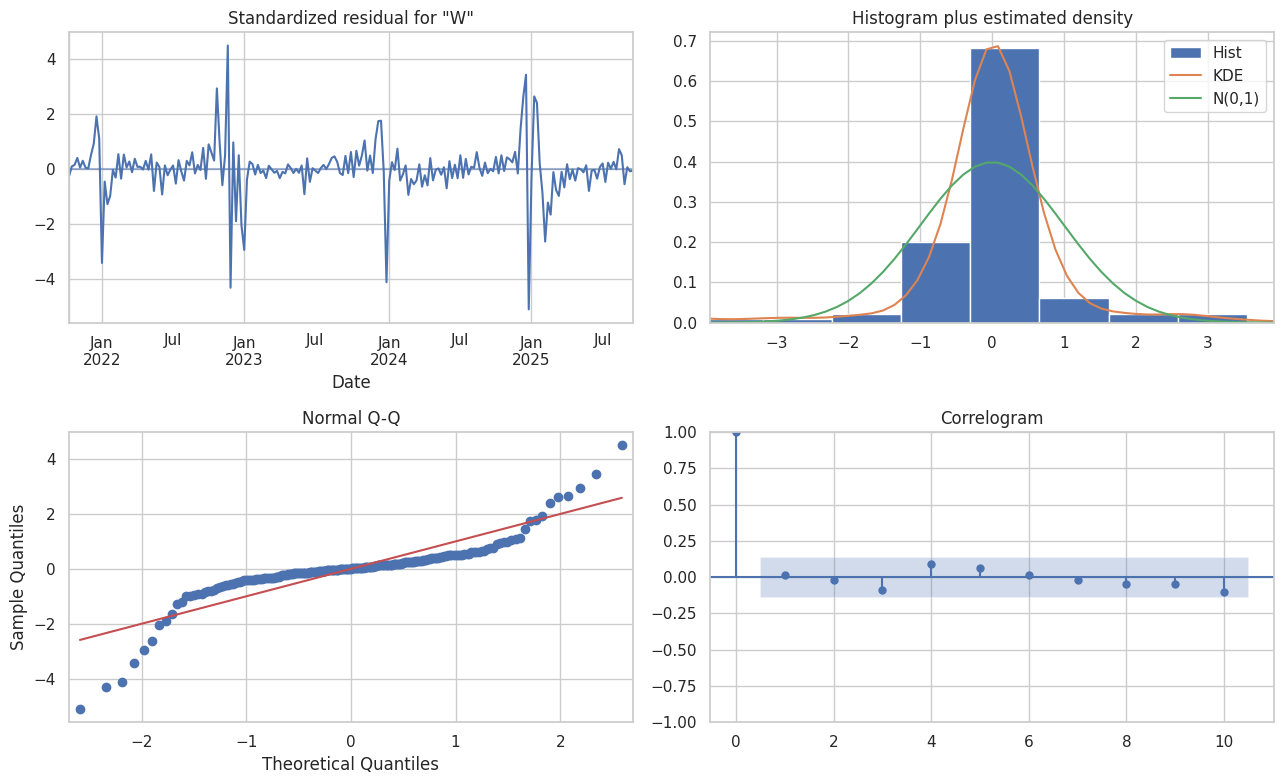


Selected ARIMAX(1, 1, 1)
                                SARIMAX Results                                 
Dep. Variable:     Weighted_ILI_Percent   No. Observations:                  208
Model:                 SARIMAX(1, 1, 1)   Log Likelihood                 -23.663
Date:                  Fri, 23 Oct 2026   AIC                             59.325
Time:                          18:10:20   BIC                             79.322
Sample:                      10-03-2021   HQIC                            67.412
                           - 09-21-2025                                         
Covariance Type:                    opg                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Thanksgiving     0.2406      0.033      7.282      0.000       0.176       0.305
Christmas        0.5598      0.042     13.365      0.000       0.478       0.642
Ne

,lb_stat,lb_pvalue
10,8.019935,0.431525
20,12.437823,0.823830


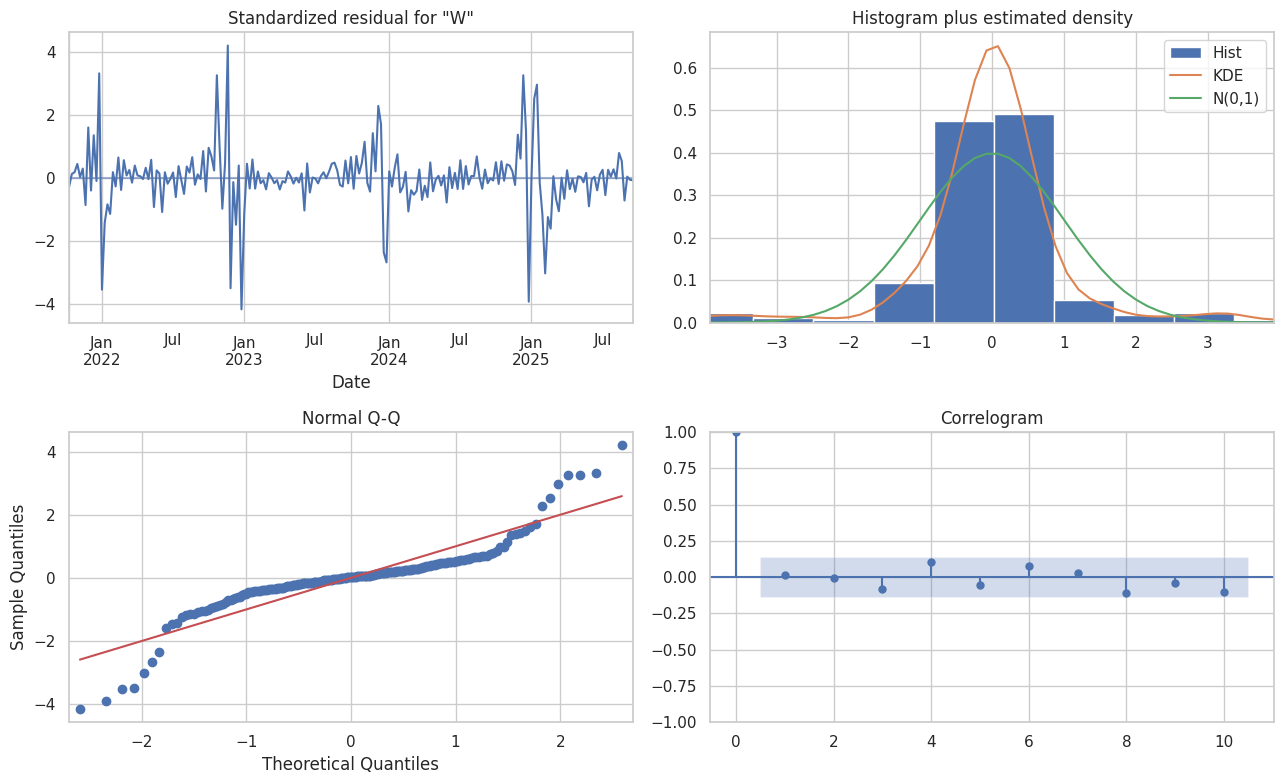

,Family,Order,Full_training_AIC,Residual_mean,Converged
0,ARIMA,"(1, 1, 1)",104.002988,-0.002979,True
1,ARIMAX,"(1, 1, 1)",59.325428,-0.002404,True


Preferred model family: ARIMAX


In [18]:
#===============================================
# iv) Model Selection and Residual Diagnostics
#===============================================

# Select the lowest validation MAE within each family.
# Refit selected models using all 208 training weeks.
best_models = {}
selected_specifications = {}
selected_model_names = {}
diagnostic_rows = []

for family in ["ARIMA", "ARIMAX"]:

    eligible_models = comparison.loc[
        (comparison["Family"] == family)
        & comparison["Validation_MAE"].notna()
        & (comparison["Failed_fits"] == 0)
    ].sort_values("Validation_MAE")

    if eligible_models.empty:
        print(
            f"No valid {family} model. "
            "Check model_fit_warnings.csv."
        )
        continue

    best_row = eligible_models.iloc[0]

    best_order = tuple(
        int(best_row[column])
        for column in ["p", "d", "q"]
    )

    selected_model_names[family] = best_row["Model"]

    fitted_model, messages = fit_candidate(
        y_train,
        X_train,
        best_order,
        family
    )

    best_models[family] = fitted_model

    selected_specifications[family] = {
        "order": list(best_order),
        "trend": "c" if best_order[1] == 0 else "n",
        "holiday_columns": (
            X_train.columns.tolist()
            if family == "ARIMAX"
            else []
        ),
        "validation_MAE": float(best_row["Validation_MAE"]),
        "final_fit_warnings": messages
    }

    print(f"\nSelected {family}{best_order}")
    print(fitted_model.summary())

    with open(
        OUTPUT / f"model_{family.lower()}_summary.txt",
        "w"
    ) as file:
        file.write(fitted_model.summary().as_text())

    # Remove early residuals affected by model initialization.
    burn_in = max(10, fitted_model.loglikelihood_burn)

    residuals = fitted_model.resid.iloc[burn_in:]

    # Test whether residual autocorrelation remains.
    ljung_box = acorr_ljungbox(
        residuals,
        lags=[10, 20],
        model_df=best_order[0] + best_order[2],
        return_df=True
    )

    print("\nLjung–Box residual test:")
    display(ljung_box)

    ljung_box.to_csv(
        OUTPUT / f"model_{family.lower()}_ljung_box.csv",
        index_label="Lag"
    )

    diagnostic_rows.append({
        "Family": family,
        "Order": str(best_order),
        "Full_training_AIC": float(fitted_model.aic),
        "Residual_mean": float(residuals.mean()),
        "Converged": bool(
            fitted_model.mle_retvals.get("converged", False)
        )
    })

    # Examine residual patterns, distribution, and autocorrelation.
    fig = fitted_model.plot_diagnostics(
        figsize=(13, 8)
    )

    fig.tight_layout()

    fig.savefig(
        OUTPUT / f"model_{family.lower()}_residual_diagnostics.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

if not best_models:
    raise RuntimeError(
        "No models were selected. Review model_fit_warnings.csv."
    )

# Identify the preferred family using validation performance only.
preferred_family = min(
    best_models,
    key=lambda family: (
        selected_specifications[family]["validation_MAE"]
    )
)

selected_specifications["preferred_family"] = preferred_family

with open(
    OUTPUT / "model_selected_specifications.json",
    "w"
) as file:
    json.dump(selected_specifications, file, indent=2)

diagnostic_table = pd.DataFrame(diagnostic_rows)

diagnostic_table.to_csv(
    OUTPUT / "model_final_fit_diagnostics.csv",
    index=False
)

display(diagnostic_table)
print("Preferred model family:", preferred_family)

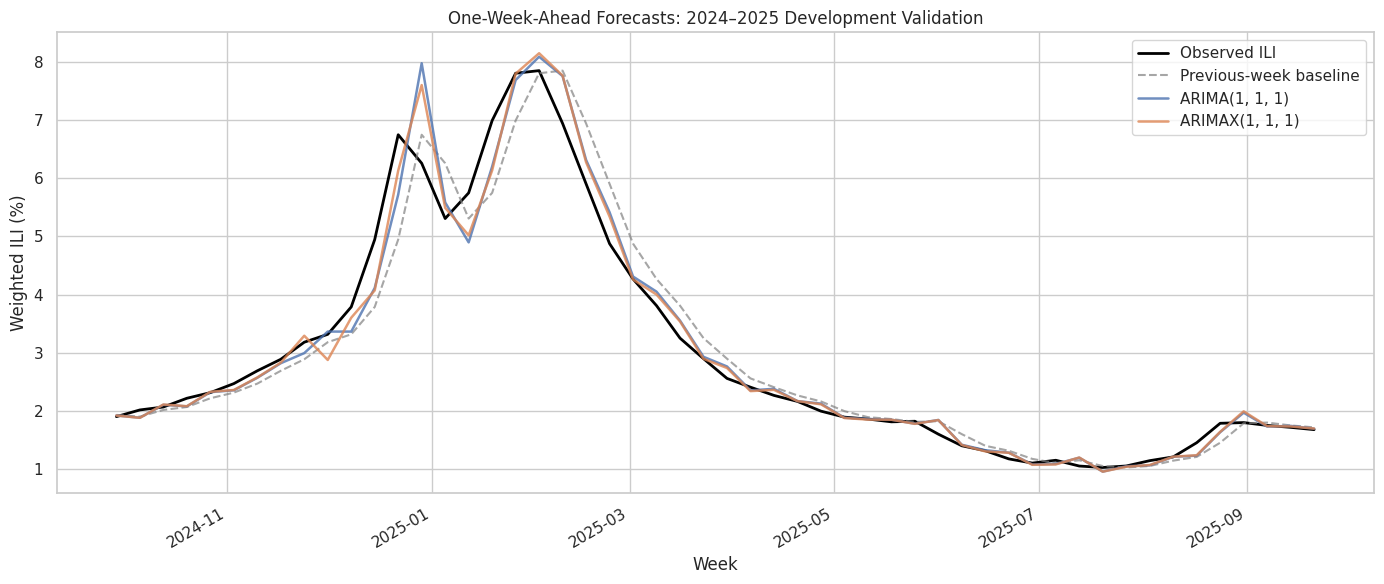

In [19]:
#===============================================
# v) Comparing Validation Forecasts
#===============================================

# Run the preceding model cells before running this plot.
if not selected_model_names:
    raise ValueError(
        "No selected models found. Run the model selection cell first."
    )

validation_dates = y_train.index[split_position:]

fig, ax = plt.subplots(figsize=(14, 6))

# Plot observed ILI and the previous-week baseline.
ax.plot(
    validation_dates,
    actual_validation,
    color="black",
    linewidth=2,
    label="Observed ILI"
)

ax.plot(
    validation_dates,
    naive_predictions,
    color="gray",
    linestyle="--",
    alpha=0.7,
    label="Previous-week baseline"
)

# Plot the selected specification from each available family.
for family, model_name in selected_model_names.items():

    model_predictions = (
        validation_predictions.loc[
            validation_predictions["Model"] == model_name
        ]
        .sort_values("Date")
        .copy()
    )

    if (
        len(model_predictions) != len(validation_dates)
        or model_predictions["Prediction"].isna().any()
    ):
        raise ValueError(
            f"Incomplete validation predictions for {model_name}."
        )

    ax.plot(
        pd.to_datetime(model_predictions["Date"]).to_numpy(),
        model_predictions["Prediction"].to_numpy(dtype=float),
        linewidth=1.8,
        alpha=0.8,
        label=model_name
    )

ax.set_title(
    "One-Week-Ahead Forecasts: 2024–2025 Development Validation"
)

ax.set_xlabel("Week")
ax.set_ylabel("Weighted ILI (%)")
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    OUTPUT / "model_validation_forecasts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Final test model: ARIMAX(1, 1, 1)
Final test weeks: 53
Final test period: 2025-09-28 to 2026-09-27


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  

,Model,Test_MAE,Naive_Test_MAE,Improvement_Percent,Goal_At_Least_10_Percent,Test_Weeks
0,"ARIMAX(1, 1, 1)",0.213082,0.306292,30.431775,True,53


Model test MAE: 0.2131
Naive baseline test MAE: 0.3063
Improvement over baseline: 30.4%
10% performance goal achieved: True


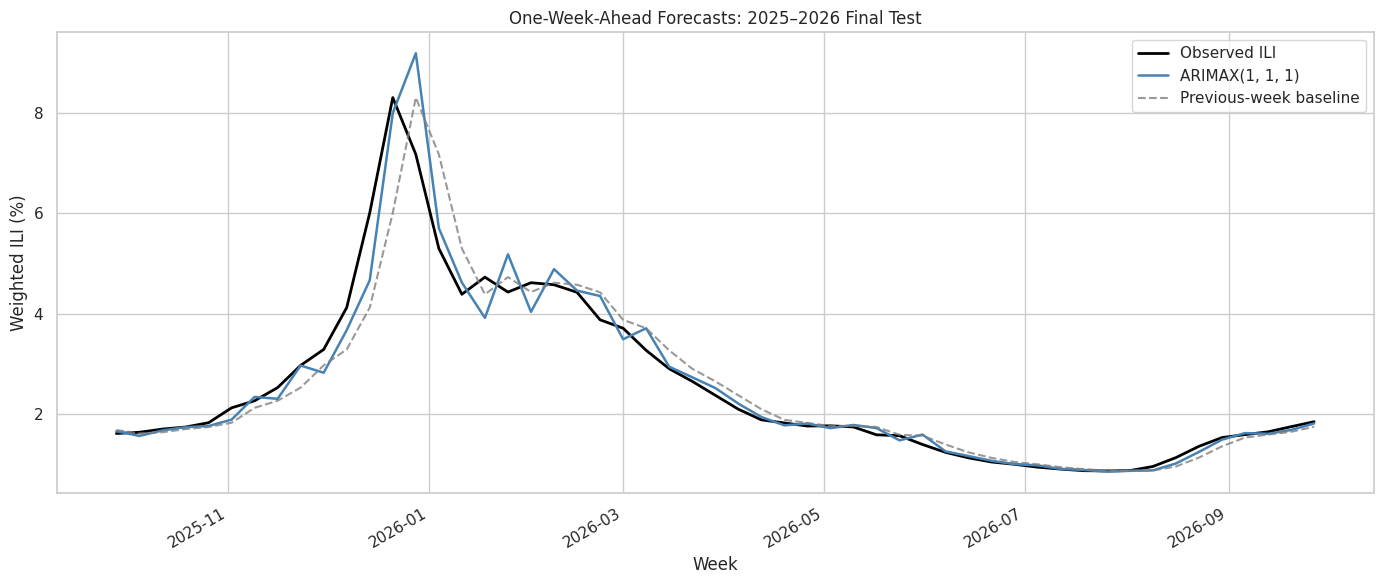

In [20]:
#===============================================
# Part IV - Final Model Testing on the 2025–2026 Influenza Season
#===============================================


# Preparing the Final Test Data
# Start from the raw 2025–2026 file (df2), keep only year, week, and
# weighted ILI, and rename the columns to match the training data.
test_data = df2.copy()
test_data.columns = test_data.columns.str.strip()
test_data = test_data[["YEAR", "WEEK", "% WEIGHTED ILI"]].copy()
test_data.columns = ["Year", "Week", "Weighted_ILI_Percent"]

# Convert columns to numbers; errors='raise' stops the run if any value
# cannot be converted.
for column in ["Year", "Week", "Weighted_ILI_Percent"]:
    test_data[column] = pd.to_numeric(
        test_data[column],
        errors="raise"
    )


# Converting Year and Week to Weekly Dates
# get_week_start (defined in Part III) returns the Sunday that begins
# each MMWR week, giving a regular weekly date index.
test_data["Date"] = [
    get_week_start(year, week)
    for year, week in zip(
        test_data["Year"],
        test_data["Week"]
    )
]


# Restricting the Test Data to the 2025–2026 Influenza Season
# Keep only 2025 week 40 through 2026 week 39.
test_data = (
    test_data.loc[
        (test_data["Date"] >= get_week_start(2025, 40))
        & (test_data["Date"] < get_week_start(2026, 40))
    ]
    .sort_values("Date")
    .set_index("Date")
)


# Checking the Final Test Data
# Stop the run if the test data have missing values, duplicate weeks,
# the wrong number of weeks, gaps between weeks, or impossible percentages.
if test_data.isna().any().any():
    raise ValueError(
        "Missing values found in the final test data."
    )

if test_data.index.duplicated().any():
    raise ValueError(
        "Duplicate reporting weeks found in the final test data."
    )

if len(test_data) != 53:
    raise ValueError(
        f"Expected 53 final test weeks, found {len(test_data)}."
    )

test_gaps = test_data.index.to_series().diff().dropna()

if not test_gaps.eq(pd.Timedelta(days=7)).all():
    raise ValueError(
        "Missing or irregular weeks found in the final test data."
    )

if not test_data["Weighted_ILI_Percent"].between(0, 100).all():
    raise ValueError(
        "Final test ILI percentages must be between 0 and 100."
    )


# Creating the Test Outcome and Holiday Variables
# Set a weekly (Sunday) frequency so forecasts line up with the dates.
y_test = test_data[
    "Weighted_ILI_Percent"
].asfreq("W-SUN")

# Build the same Thanksgiving, Christmas, and New Year indicators
# used during training.
X_test = create_holiday_features(y_test.index)


# Loading the Model Selected During Validation
# The model family and order were fixed during Part III validation
# and are not changed after seeing the test data.
final_family = selected_specifications[
    "preferred_family"
]

final_order = tuple(
    selected_specifications[final_family]["order"]
)

print(
    "Final test model:",
    f"{final_family}{final_order}"
)

print(
    "Final test weeks:",
    len(y_test)
)

print(
    "Final test period:",
    y_test.index.min().date(),
    "to",
    y_test.index.max().date()
)


# Initializing the Expanding Training History
# Start from all 208 training weeks. Each test week is added only after
# it has been forecast, so every forecast uses only earlier observations.
history = y_train.copy()
holiday_history = X_train.copy()

test_prediction_rows = []
test_warning_rows = []


# Generating One-Week-Ahead Final Test Forecasts
for test_date, actual_value in y_test.items():

    # Calendar holiday indicators for the week being forecast.
    target_holidays = X_test.loc[[test_date]]

    # Naive baseline: predict that this week equals last week's observed value.
    naive_prediction = float(
        history.iloc[-1]
    )

    try:
        # Refit the selected model on all data available before this week,
        # using the same fitting function as in validation.
        fitted_model, messages = fit_candidate(
            history,
            holiday_history,
            final_order,
            final_family
        )

        # Forecast one week ahead.
        forecast_result = fitted_model.forecast(
            steps=1,
            exog=(
                target_holidays
                if final_family == "ARIMAX"
                else None
            )
        )

        model_prediction = float(
            np.asarray(
                forecast_result
            ).reshape(-1)[0]
        )

        # Treat infinite or missing forecasts as failures.
        if not np.isfinite(model_prediction):
            raise ValueError(
                "Nonfinite final test forecast."
            )

        # Log non-fatal warnings from this fit.
        for message in messages:
            test_warning_rows.append({
                "Model": f"{final_family}{final_order}",
                "Date": test_date,
                "Message": message
            })

    # If the fit or forecast fails, record NaN and log the error.
    except Exception as error:
        model_prediction = np.nan

        test_warning_rows.append({
            "Model": f"{final_family}{final_order}",
            "Date": test_date,
            "Message": str(error)
        })


    # Recording the Model, Baseline, and Actual Values
    test_prediction_rows.append({
        "Date": test_date,
        "Actual": float(actual_value),
        "Model_Prediction": model_prediction,
        "Naive_Prediction": naive_prediction
    })


    # Adding the Observed Test Week to the Expanding History
    new_observation = pd.Series(
        [float(actual_value)],
        index=pd.DatetimeIndex([test_date]),
        name=history.name
    )

    history = pd.concat([
        history,
        new_observation
    ])

    holiday_history = pd.concat([
        holiday_history,
        target_holidays
    ])


# Creating the Final Test Prediction Table
test_predictions = pd.DataFrame(
    test_prediction_rows
)


# Checking for Failed Test Forecasts
if test_predictions[
    "Model_Prediction"
].isna().any():

    failed_weeks = int(
        test_predictions[
            "Model_Prediction"
        ].isna().sum()
    )

    raise RuntimeError(
        f"The final model failed for {failed_weeks} "
        "test week(s). Review the test warning output."
    )


# Calculating the Weekly Absolute Errors
test_predictions[
    "Model_Absolute_Error"
] = (
    test_predictions["Actual"]
    - test_predictions["Model_Prediction"]
).abs()

test_predictions[
    "Naive_Absolute_Error"
] = (
    test_predictions["Actual"]
    - test_predictions["Naive_Prediction"]
).abs()


# Calculating the Final Test MAE
model_test_mae = float(
    test_predictions[
        "Model_Absolute_Error"
    ].mean()
)

naive_test_mae = float(
    test_predictions[
        "Naive_Absolute_Error"
    ].mean()
)


# Calculating Improvement over the Naive Baseline
improvement_percent = float(
    100 * (
        1
        - model_test_mae
        / naive_test_mae
    )
)

# The performance goal is met if model MAE is at least 10% lower than
# the baseline MAE (model MAE <= 0.90 x baseline MAE).
goal_achieved = bool(
    improvement_percent >= 10
)


# Creating the Final Test Comparison Table
test_comparison = pd.DataFrame([{
    "Model": f"{final_family}{final_order}",
    "Test_MAE": model_test_mae,
    "Naive_Test_MAE": naive_test_mae,
    "Improvement_Percent": improvement_percent,
    "Goal_At_Least_10_Percent": goal_achieved,
    "Test_Weeks": len(test_predictions)
}])


# Creating the Model Warning Table
test_warnings = pd.DataFrame(
    test_warning_rows,
    columns=[
        "Model",
        "Date",
        "Message"
    ]
)


# Saving the Final Test Results
test_predictions.to_csv(
    OUTPUT / "model_test_predictions.csv",
    index=False
)

test_comparison.to_csv(
    OUTPUT / "model_test_comparison.csv",
    index=False
)

test_warnings.to_csv(
    OUTPUT / "model_test_fit_warnings.csv",
    index=False
)


# Displaying the Final Test Results
display(test_comparison)

print(
    f"Model test MAE: "
    f"{model_test_mae:.4f}"
)

print(
    f"Naive baseline test MAE: "
    f"{naive_test_mae:.4f}"
)

print(
    f"Improvement over baseline: "
    f"{improvement_percent:.1f}%"
)

print(
    f"10% performance goal achieved: "
    f"{goal_achieved}"
)


# Plotting the Final Test Forecasts
fig, ax = plt.subplots(
    figsize=(14, 6)
)

ax.plot(
    test_predictions["Date"],
    test_predictions["Actual"],
    color="black",
    linewidth=2,
    label="Observed ILI"
)

ax.plot(
    test_predictions["Date"],
    test_predictions["Model_Prediction"],
    color="steelblue",
    linewidth=1.8,
    label=f"{final_family}{final_order}"
)

ax.plot(
    test_predictions["Date"],
    test_predictions["Naive_Prediction"],
    color="gray",
    linestyle="--",
    alpha=0.8,
    label="Previous-week baseline"
)

ax.set_title(
    "One-Week-Ahead Forecasts: "
    "2025–2026 Final Test"
)

ax.set_xlabel("Week")
ax.set_ylabel("Weighted ILI (%)")
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()


# Saving the Final Test Forecast Plot
fig.savefig(
    OUTPUT / "model_test_forecasts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()